In [1]:
## ---- 1. Install / Load Required Packages --------------------
required_packages <- c("igraph", "ggraph", "ggplot2")

for (pkg in required_packages) {
  if (!require(pkg, character.only = TRUE)) {
    install.packages(pkg, repos = "https://cran.r-project.org")
    library(pkg, character.only = TRUE)
  }
}


Loading required package: igraph

Warning message in library(package, lib.loc = lib.loc, character.only = TRUE, logical.return = TRUE, :
“there is no package called ‘igraph’”
Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘igraph’


The following objects are masked from ‘package:stats’:

    decompose, spectrum


The following object is masked from ‘package:base’:

    union


Loading required package: ggraph

Warning message in library(package, lib.loc = lib.loc, character.only = TRUE, logical.return = TRUE, :
“there is no package called ‘ggraph’”
Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘tweenr’, ‘polyclip’, ‘gridExtra’, ‘RcppArmadillo’, ‘ggforce’, ‘ggrepel’, ‘viridis’, ‘tidygraph’, ‘graphlayouts’


Loading required package: ggplot2



In [2]:
## ---- 2. Import / Prepare Network Data ------------------------
# setwd("path/to/your/folder")  # set your working directory

edges <- data.frame(
  from = c("Alice","Alice","Alice","Bob","Bob","Carol","Carol","David","Eve","Eve",
            "Frank","Frank","Grace","Heidi","Ivan","Judy","Judy","Ivan","Grace","Heidi"),
  to   = c("Bob","Carol","David","Carol","Eve","David","Eve","Frank","Frank","Grace",
            "Grace","Heidi","Heidi","Ivan","Judy","Alice","Bob","Carol","Alice","Bob")
)

head(edges)

,from,to
,<chr>,<chr>
1,Alice,Bob
2,Alice,Carol
3,Alice,David
4,Bob,Carol
5,Bob,Eve
6,Carol,David


In [3]:
## ---- 3. Represent the Network as a Graph Object --------------
g <- graph_from_data_frame(edges, directed = FALSE)
g <- simplify(g)

cat("Number of nodes:", vcount(g), "\n")
cat("Number of edges:", ecount(g), "\n")

Number of nodes: 10 
Number of edges: 20 


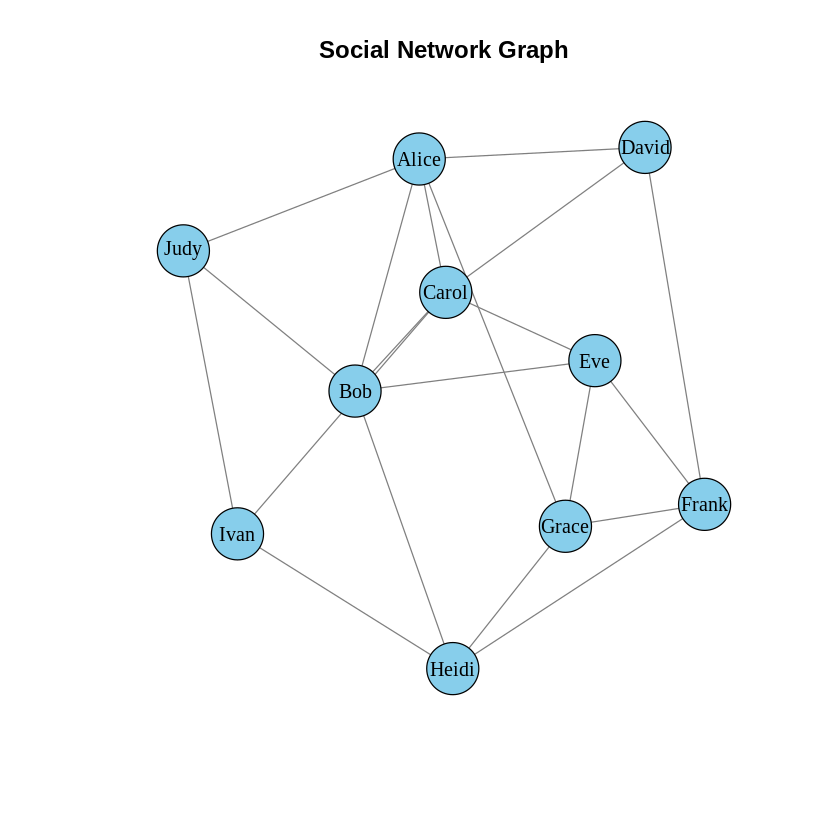

In [4]:
## ---- 4. Basic Network Visualization ---------------------------
set.seed(123)
plot(g,
     vertex.color = "skyblue",
     vertex.size = 20,
     vertex.label.color = "black",
     edge.color = "gray50",
     main = "Social Network Graph")

In [5]:
## ---- 5. Compute Network / Centrality Measures ------------------
degree_centrality      <- degree(g)
betweenness_centrality <- betweenness(g)
closeness_centrality   <- closeness(g)
eigen_centrality_score <- eigen_centrality(g)$vector

results <- data.frame(
  Node        = names(degree_centrality),
  Degree      = degree_centrality,
  Betweenness = round(betweenness_centrality, 3),
  Closeness   = round(closeness_centrality, 3),
  Eigenvector = round(eigen_centrality_score, 3)
)

results <- results[order(-results$Degree), ]
print(results)

       Node Degree Betweenness Closeness Eigenvector
Alice Alice      5       4.567     0.077       0.971
Bob     Bob      5       3.900     0.077       1.000
Carol Carol      5       4.167     0.077       0.971
Eve     Eve      4       2.033     0.071       0.844
Frank Frank      4       2.333     0.067       0.731
Grace Grace      4       1.867     0.071       0.795
Heidi Heidi      4       3.567     0.071       0.745
David David      3       1.200     0.067       0.645
Ivan   Ivan      3       1.533     0.067       0.562
Judy   Judy      3       0.833     0.062       0.611


In [6]:
## ---- 6. Identify Influential / Important Nodes -----------------
most_connected <- results$Node[which.max(results$Degree)]
most_between   <- results$Node[which.max(results$Betweenness)]
most_close     <- results$Node[which.max(results$Closeness)]
most_eigen     <- results$Node[which.max(results$Eigenvector)]

cat("Most connected (Degree):        ", most_connected, "\n")
cat("Key broker/bridge (Betweenness):", most_between, "\n")
cat("Most central (Closeness):       ", most_close, "\n")
cat("Most influential (Eigenvector): ", most_eigen, "\n")

Most connected (Degree):         Alice 
Key broker/bridge (Betweenness): Alice 
Most central (Closeness):        Alice 
Most influential (Eigenvector):  Bob 


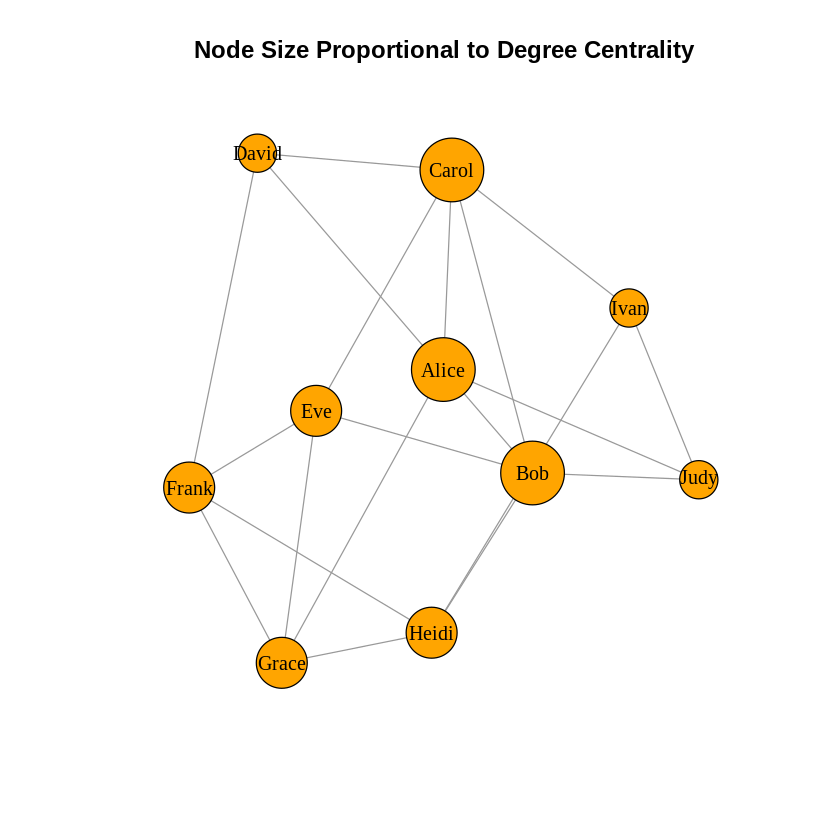

In [7]:
## ---- 7. Enhanced Visualization: Node Size by Degree -------------
V(g)$degree <- degree(g)

plot(g,
     vertex.size = V(g)$degree * 5,
     vertex.color = "orange",
     vertex.label.color = "black",
     edge.color = "gray60",
     main = "Node Size Proportional to Degree Centrality")

Number of communities detected: 2 
Alice   Bob Carol David   Eve Frank Grace Heidi  Ivan  Judy 
    1     1     1     1     2     2     2     2     1     1 


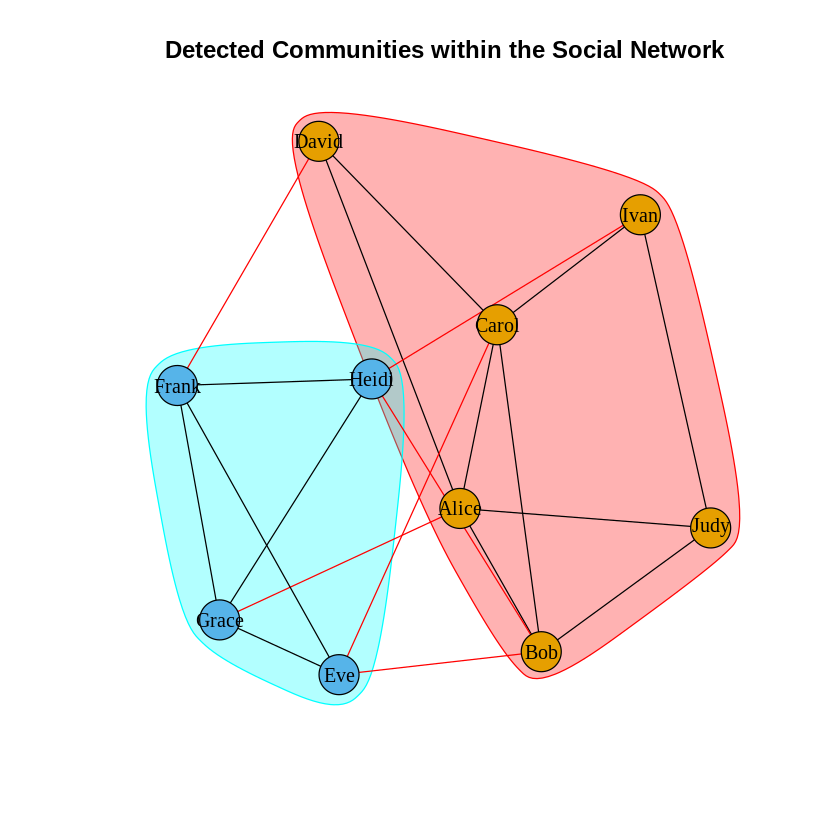

In [8]:
## ---- 8. Community Detection (Bonus) -----------------------------
communities <- cluster_louvain(g)
cat("Number of communities detected:", length(communities), "\n")
print(membership(communities))

plot(communities, g,
     vertex.label.color = "black",
     main = "Detected Communities within the Social Network")

In [9]:
## ---- 9. Overall Network-Level Metrics ----------------------------
cat("Network density:      ", round(edge_density(g), 3), "\n")
cat("Average path length:  ", round(mean_distance(g), 3), "\n")
cat("Network diameter:     ", diameter(g), "\n")
cat("Global clustering coeff:", round(transitivity(g, type = "global"), 3), "\n")

Network density:       0.444 
Average path length:   1.578 
Network diameter:      3 
Global clustering coeff: 0.286 
